<a href="https://colab.research.google.com/github/sen-soumya/Optical-communication/blob/main/Multi-Modal%20Fiber%20Optic%20Distributed%20Sensing%20Systems.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### 1. Setup & Data Generator

In [2]:
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt

SENSING_MODES = {
    0: {"name": "Seismic Activity", "freq": 2.0, "duration": 500, "span_km": 15.0},
    1: {"name": "Perimeter Intrusion", "freq": 45.0, "duration": 80, "span_km": 0.2},
    2: {"name": "Pipeline Leak", "freq": 250.0, "duration": 400, "span_km": 1.5},
    3: {"name": "Structural Stress", "freq": 120.0, "duration": 150, "span_km": 0.5}
}

def generate_fiber_sensing_dataset(samples_per_mode=400, sample_points=512):
    X_data = []
    Y_labels = []
    t = np.linspace(0, 1.0, sample_points)

    for mode_idx, profile in SENSING_MODES.items():
        freq = profile["freq"]
        span = profile["span_km"]

        for _ in range(samples_per_mode):
            signal = np.sin(2 * np.pi * freq * t)
            envelope = np.exp(-((t - 0.5) ** 2) / (2 * (span / 20.0) ** 2))
            modulated_waveform = signal * envelope
            noise = np.random.normal(0, 0.25, size=sample_points)
            final_waveform = modulated_waveform + noise

            X_data.append(final_waveform)
            Y_labels.append(mode_idx)

    return torch.tensor(np.array(X_data), dtype=torch.float32).unsqueeze(1), torch.tensor(np.array(Y_labels), dtype=torch.long)

X, Y = generate_fiber_sensing_dataset()

### 2. Signal Visualization

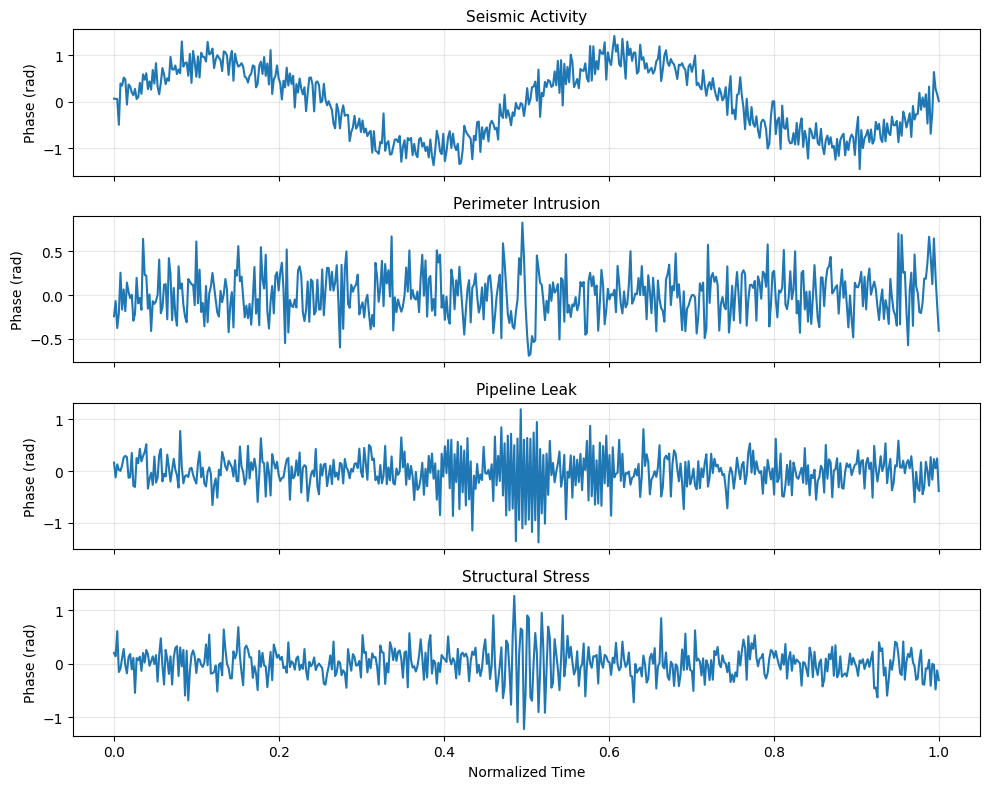

In [3]:
fig, axes = plt.subplots(4, 1, figsize=(10, 8), sharex=True)
t_plot = np.linspace(0, 1.0, 512)

for idx, profile in SENSING_MODES.items():
    sample_mask = (Y.numpy() == idx)
    sample_wave = X.numpy()[sample_mask][0][0]

    axes[idx].plot(t_plot, sample_wave, lw=1.5)
    axes[idx].set_title(profile['name'], fontsize=11)
    axes[idx].set_ylabel("Phase (rad)")
    axes[idx].grid(True, alpha=0.3)

axes[-1].set_xlabel("Normalized Time")
plt.tight_layout()
plt.show()

### 3. Model Architecture

In [4]:
class FiberSensingClassifier(nn.Module):
    def __init__(self, num_classes=4):
        super(FiberSensingClassifier, self).__init__()
        self.feature_extractor = nn.Sequential(
            nn.Conv1d(in_channels=1, out_channels=16, kernel_size=7, stride=2, padding=3),
            nn.BatchNorm1d(16),
            nn.ReLU(),
            nn.MaxPool1d(kernel_size=2),

            nn.Conv1d(in_channels=16, out_channels=32, kernel_size=5, stride=1, padding=2),
            nn.BatchNorm1d(32),
            nn.ReLU(),
            nn.MaxPool1d(kernel_size=2),

            nn.Flatten()
        )

        self.classifier = nn.Sequential(
            nn.Linear(32 * 64, 64),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(64, num_classes)
        )

    def forward(self, x):
        features = self.feature_extractor(x)
        return self.classifier(features)

### 4. Training & Validation

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X.numpy(), Y.numpy(), test_size=0.25, random_state=42, stratify=Y.numpy()
)

train_loader = DataLoader(TensorDataset(torch.tensor(X_train), torch.tensor(y_train)), batch_size=64, shuffle=True)
test_loader = DataLoader(TensorDataset(torch.tensor(X_test), torch.tensor(y_test)), batch_size=64, shuffle=False)

model = FiberSensingClassifier(num_classes=4)
optimizer = optim.Adam(model.parameters(), lr=0.001)
criterion = nn.CrossEntropyLoss()

for epoch in range(15):
    model.train()
    running_loss = 0.0
    for batch_x, batch_y in train_loader:
        optimizer.zero_grad()
        outputs = model(batch_x)
        loss = criterion(outputs, batch_y)
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * batch_x.size(0)

    model.eval()
    correct = 0
    total = 0
    with torch.no_grad():
        for batch_x, batch_y in test_loader:
            outputs = model(batch_x)
            predictions = torch.argmax(outputs, dim=1)
            total += batch_y.size(0)
            correct += (predictions == batch_y).sum().item()

    print(f"Epoch {epoch+1:02d}/15 | Loss: {running_loss/len(X_train):.4f} | Val Acc: {(correct/total)*100:.2f}%")

Epoch 01/15 | Loss: 0.3599 | Val Acc: 100.00%
Epoch 02/15 | Loss: 0.0099 | Val Acc: 100.00%
Epoch 03/15 | Loss: 0.0016 | Val Acc: 100.00%
Epoch 04/15 | Loss: 0.0014 | Val Acc: 100.00%
Epoch 05/15 | Loss: 0.0011 | Val Acc: 100.00%
Epoch 06/15 | Loss: 0.0007 | Val Acc: 100.00%
Epoch 07/15 | Loss: 0.0005 | Val Acc: 100.00%
Epoch 08/15 | Loss: 0.0006 | Val Acc: 100.00%
Epoch 09/15 | Loss: 0.0003 | Val Acc: 100.00%
Epoch 10/15 | Loss: 0.0003 | Val Acc: 100.00%
Epoch 11/15 | Loss: 0.0004 | Val Acc: 100.00%
Epoch 12/15 | Loss: 0.0004 | Val Acc: 100.00%
Epoch 13/15 | Loss: 0.0002 | Val Acc: 100.00%
Epoch 14/15 | Loss: 0.0003 | Val Acc: 100.00%
Epoch 15/15 | Loss: 0.0005 | Val Acc: 100.00%


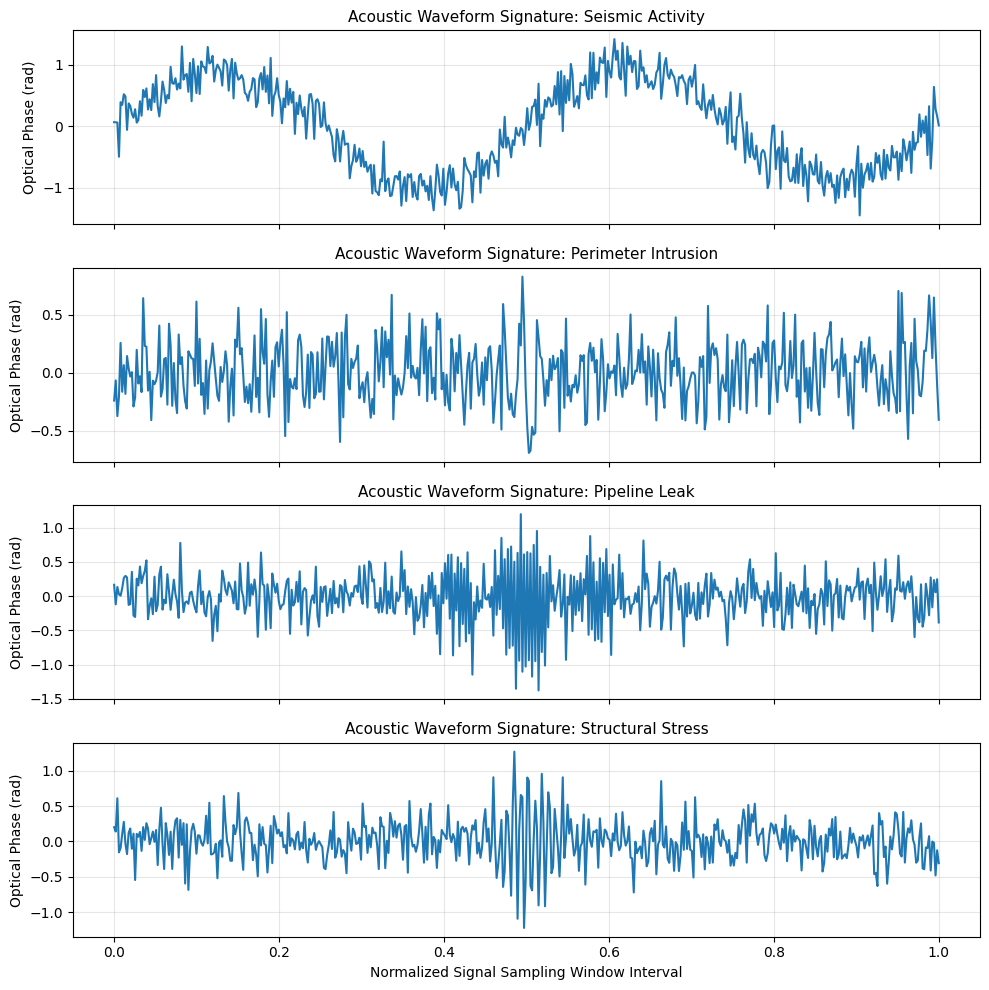

In [6]:
    fig, axes = plt.subplots(4, 1, figsize=(10, 10), sharex=True)
    t_plot = np.linspace(0, 1.0, 512)

    # Pull one clear raw waveform sample from each sensing label class to display
    for idx, profile in SENSING_MODES.items():
        sample_mask = (Y.numpy() == idx)
        sample_wave = X.numpy()[sample_mask][0][0]

        axes[idx].plot(t_plot, sample_wave, lw=1.5)
        axes[idx].set_title(f"Acoustic Waveform Signature: {profile['name']}", fontsize=11)
        axes[idx].set_ylabel("Optical Phase (rad)")
        axes[idx].grid(True, alpha=0.3)

    axes[-1].set_xlabel("Normalized Signal Sampling Window Interval")
    plt.tight_layout()
    plt.show()